# DICOM-CT-PD (3rd generation CT)

Raw projections from clinical CT scanners are rarely shared, but the DICOM-CT-PD format, developed at the Mayo Clinic, stores them together with everything needed to reconstruct them: the position of the X-ray source and the detector for every view. This tutorial reconstructs a full-dose chest scan from a GE Discovery CT750 HD, from The Cancer Imaging Archive's open LDCT-and-Projection-data collection, with filtered back projection, and compares the result with the scanner's own reconstruction.

The first part uses only the projection files. The second, advanced part shows how to reproduce the scanner's own images, which takes settings fitted to those images.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("CT/ldct-c145")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("CT/ldct-c145")

CT/ldct-c145: already downloaded


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import pytomography
from pytomography import io
from pytomography.metadata import ObjectMeta
from pytomography.io.CT import preprocessing
from pytomography.projectors.CT import CTGen3SystemMatrix
from pytomography.algorithms import FilteredBackProjection

In [3]:
# Memory: this tutorial needs about 16 GB of RAM (15.7 GB measured on Windows). RAM_GB caps what PyTomography's
# reconstructions use for their own work: with less, they rebin and filter fewer views at a time, which is a little
# slower and gives the same images. The first reconstruction prints its estimate before it runs (estimate_memory): its
# peak RAM and GPU memory, what they are made of, and what to change to use less. Most of the 16 GB is what the
# tutorial keeps (2 GB of projections, five images) and the GPU libraries, so a lower RAM_GB saves little: the
# tutorial needs about 16 GB whatever it is set to.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. Load the projections

Each of the 9,014 files is one view of the helical scan: an 888 × 64 detector reading, with the position of the source and detector at that moment. `io.CT.read_dicom_ct_pd` puts the views in acquisition order (the file names are UIDs) and takes the whole geometry from the files. It returns the projections, the object grid placed in the patient (`object_meta`, on the grid of section 2), and the projection metadata. By default it also filters rays that received too few photons, which would otherwise leave streaks between the shoulders. The files also give the attenuation of water for this scan, which converts attenuation to Hounsfield units (`io.CT.to_hu`).

In [4]:
folder = DATA / 'CT' / 'ldct-c145'
grid = ObjectMeta(dr=(0.662109, 0.662109, 1.0), shape=(512, 512, 316))  # mm, voxels: the scanner's grid (section 2)
t0 = time.time()
proj, object_meta, proj_meta = io.CT.read_dicom_ct_pd(folder / 'full_dose_projections', object_meta=grid)
print(f"{proj.shape[0]} views of {proj.shape[1]} × {proj.shape[2]} detector elements, read in {time.time() - t0:.0f} s")
print(f"water: {proj_meta.water_attenuation} mm^-1; central detector column: {float(proj_meta.detector_centers_col_idx[0])}")

9014 views of 888 × 64 detector elements, read in 54 s
water: 0.0186 mm^-1; central detector column: 443.25


GE counts the detector's central element from the other end of the detector, so for GE files the reader uses column 443.25 rather than the 444.75 stored in them. With the stored value, the rays that cross a point from opposite sides of the patient would miss each other by about 1.4 mm, and every edge would blur.

Each view is the line integral of attenuation along every ray from the source to a detector element. A few of them, a quarter of a scan apart:

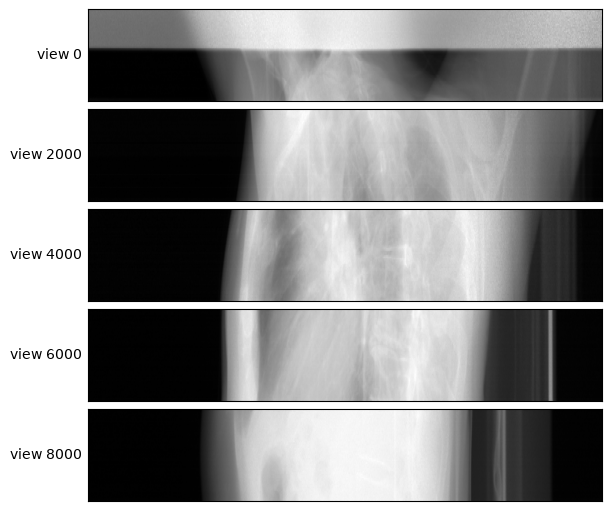

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(6, 5), constrained_layout=True)
for ax, i in zip(axes, [0, 2000, 4000, 6000, 8000]):
    ax.imshow(proj[i].T, cmap='Greys_r', aspect='auto')
    ax.set_ylabel(f'view {i}', rotation=0, ha='right', va='center')
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 2. Object space

The scanner's images are 512 × 512 pixels of 0.662109 mm (their PixelSpacing: a 339 mm field of view over 512 pixels), in slices 1 mm apart. We reconstruct on exactly the same pixel size (`grid` above), so that the comparison in section 4 does not have to interpolate between pixels, centred on the axis of rotation, with 316 slices 1 mm apart along the table: the length the scanner reconstructed. `ObjectMeta` takes the voxel size in mm, and the reader placed the grid in the patient: `object_meta.affine` gives each voxel's position, with the slices running from the feet to the head.

In [6]:
system_matrix = CTGen3SystemMatrix(object_meta, proj_meta)

## 3. Filtered back projection

`FilteredBackProjection` takes the projections and the system matrix. It rebins the helical fan beams to parallel beams, filters them, and back projects them with weights that combine the overlapping turns of the helix (WFBP). `filter` sets the window on the ramp filter: `'ram-lak'` is the sharpest and noisiest, `'hann'` smooth. `slice_thickness=1.25` makes each slice the average over 1.25 mm along the table, like the scanner's images: they are 1.25 mm thick and 1 mm apart, so they overlap. The thickness is an option of filtered back projection rather than of the object grid: the grid says where the slices are, and the reconstruction how much of the table each one averages over (the projectors and the iterative algorithms have no such option). The GPU memory it uses stays within a budget, 1.5 GB by default (`gpu_budget=`).

In [7]:
reconstruction = FilteredBackProjection(proj, system_matrix, filter='hann', slice_thickness=1.25)  # slices 1.25 mm thick
print(reconstruction.estimate_memory())  # its peak RAM and GPU memory, and what to change to use less
t0 = time.time()
fbp = reconstruction()
print(f"filtered back projection: {time.time() - t0:.0f} s")
hu = io.CT.to_hu(fbp, proj_meta).cpu().numpy()

Filtered back projection (CTGen3SystemMatrix)
Peak ~ 13.3 GB RAM, 3.7 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 2.0 GB RAM, 0.3 GB GPU (projections 2.0 RAM, image 0.3 GPU)
  projector chunks: 2.2 GB RAM, 1.9 GB GPU (rebinned views of one chunk 1.9 RAM, views being rebinned or filtered 0.2 RAM, rebinning, filtering and back projection buffers 1.9 GPU)
  Python, CUDA, allocator: 5.3 GB RAM, 1.5 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.8 GPU, memory the allocators keep (Windows) 2.3 RAM)
To use less: set_memory_budget(8) ~ 12.0 GB RAM, 3.7 GB GPU, gpu_budget=0.75e9 ~ 12.0 GB RAM, 2.7 GB GPU
(plus whatever else your script keeps)


filtered back projection: 56 s


## 4. The scanner's reconstruction

`io.load_image` reads the scanner's images with their place in the patient, and `.on(object_meta)` resamples them onto our grid. GE's `ImagePositionPatient` marks the corner of the first pixel rather than its centre, as DICOM defines it; `load_image` knows this rule of GE's (PyTomography's vendor table), so nothing needs correcting here.

In [8]:
scanner_files = sorted((folder / 'full_dose_images').glob('*.dcm'))
scanner = io.load_image(scanner_files)  # in HU, with its place in the patient
scanner_hu = scanner.on(object_meta, fill=-3000).cpu().numpy()  # -3000: no scanner image here

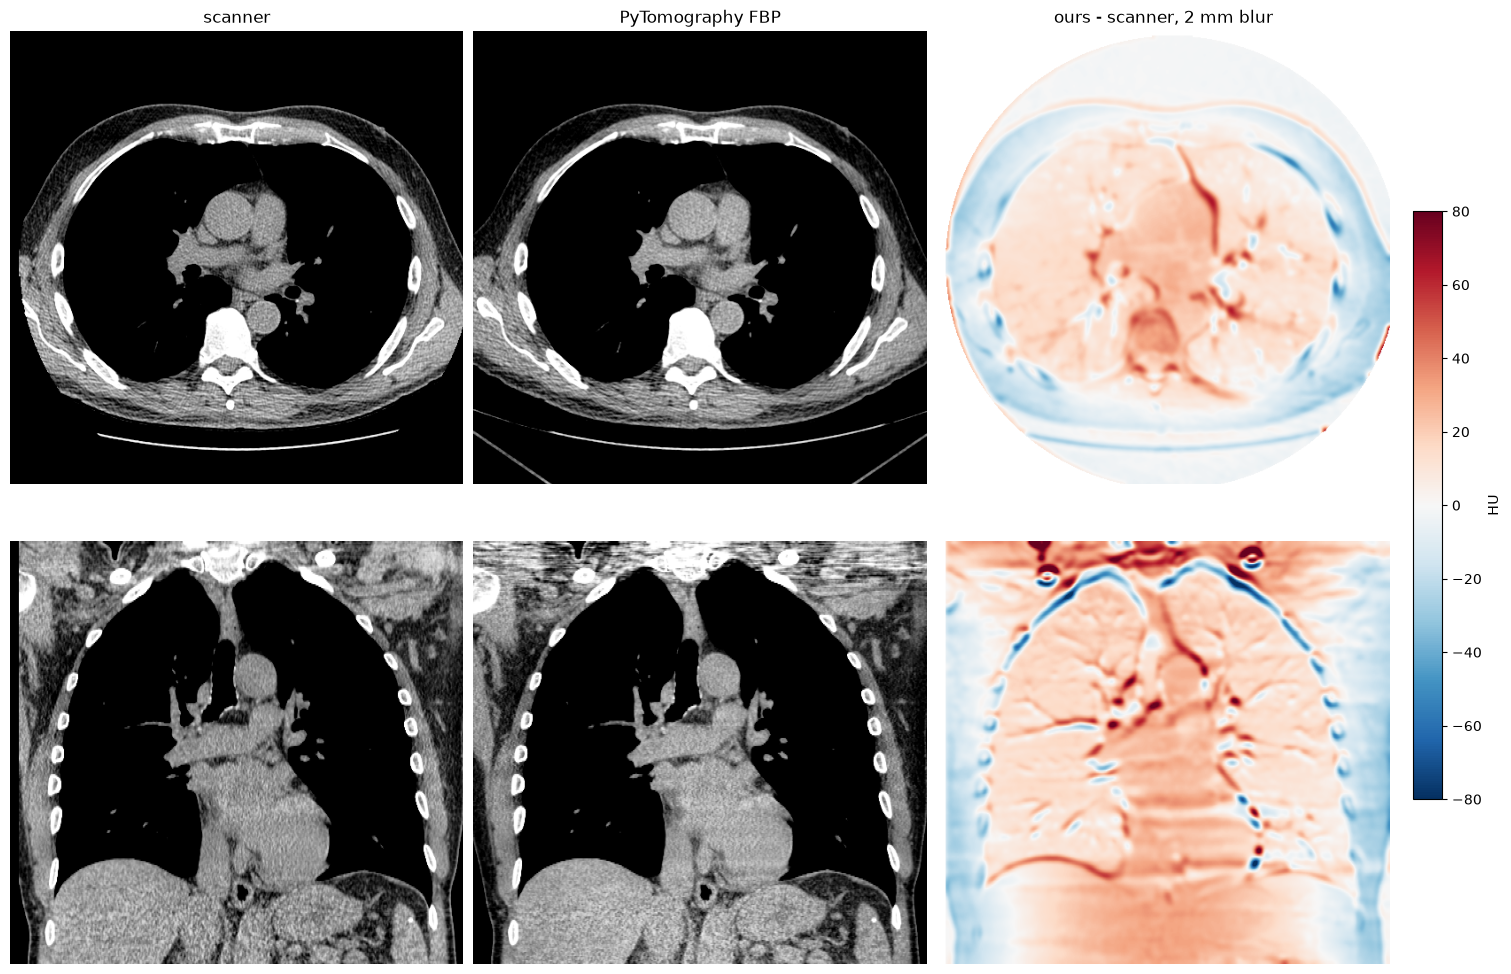

RMS difference over the body after a 2 mm blur: 21.2 HU


In [9]:
k, j = 157, 256  # an axial slice through the chest, a coronal slice through the middle (k runs from the feet up)
dx, dz = object_meta.dr[0], object_meta.dr[2]
# The body and the soft tissue of the scanner's images (above -700 HU after a 2 mm blur; 10 to 70 HU after a 7 x 7 x 3
# voxel mean, eroded): they come with the dataset, in its folder
regions = io.load_mask(folder / 'ldct_c145_rois.seg.nrrd')
r = np.hypot(*np.meshgrid(*[(np.arange(n) - (n - 1) / 2) * dx for n in object_meta.shape[:2]], indexing='ij'))[:, :, None]

def blurred(a, valid):
    # 2 mm Gaussian blur, with everything outside the scanner's field of view set to air
    return ndimage.gaussian_filter(np.where(valid, a, -1000.0), (2 / dx, 2 / dx, 2 / dz))

def compare(ours, title):
    valid = scanner_hu > -1500  # inside the scanner's field of view (it pads outside with a lower value)
    diff = np.where(valid, blurred(ours, valid) - blurred(scanner_hu, valid), np.nan)
    body = valid & regions.on(object_meta, label='body', threshold=0.5).cpu().numpy()
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
    # axial: anterior at the top; coronal: the head at the top
    for row, cut, aspect, origin in ((0, lambda a: a[:, :, k].T, 1, 'upper'), (1, lambda a: a[:, j, :].T, dz / dx, 'lower')):
        axes[row, 0].imshow(cut(scanner_hu), cmap='Greys_r', vmin=-160, vmax=240, aspect=aspect, origin=origin)
        axes[row, 1].imshow(cut(ours), cmap='Greys_r', vmin=-160, vmax=240, aspect=aspect, origin=origin)
        im = axes[row, 2].imshow(cut(diff), cmap='RdBu_r', vmin=-80, vmax=80, aspect=aspect, origin=origin)
    for ax, t in zip(axes[0], ('scanner', title, 'ours - scanner, 2 mm blur')):
        ax.set_title(t)
    for ax in axes.flat:
        ax.axis('off')
    fig.colorbar(im, ax=axes[:, 2], shrink=0.6, label='HU')
    plt.show()
    print(f"RMS difference over the body after a 2 mm blur: {np.sqrt((diff[body] ** 2).mean()):.1f} HU")

def radial_trend(ours):
    # mean of ours - scanner in soft tissue, in 20 mm rings
    valid = scanner_hu > -1500
    soft_tissue = valid & regions.on(object_meta, label='soft_tissue', threshold=0.5).cpu().numpy()
    edges = np.arange(0, 201, 20)
    d = ours - scanner_hu
    return edges[:-1] + 10, [d[soft_tissue & (r >= a) & (r < b)].mean() for a, b in zip(edges[:-1], edges[1:])]

compare(hu, 'PyTomography FBP')
trend_basic = radial_trend(hu)

The two images line up and show the same anatomy, with the same edges. Two differences remain, and neither is in the projection files: ours is smoother (the Hann window against the scanner's STANDARD kernel), and soft tissue reads about 25 HU higher than the scanner's at the centre and about 20 HU lower at the edge of the body, red and blue in the difference image (plotted against the distance from the axis at the end of this tutorial). Both come from what the scanner does when it reconstructs.

## Advanced: reproducing the scanner's own images

This part needs the scanner's own images of the same scan. Three settings make our reconstruction reproduce them:

| Setting | What it does | Where it comes from |
|---|---|---|
| `table_feed='pitch'` | puts our slices where the scanner's are: the scanner's images use the nominal table feed, 0.2% less than the focal spot positions in the files | the projection files (SpiralPitchFactor) |
| a per-column scale | the calibration of each detector column that the scanner applies when it reconstructs; it removes the radial trend | fitted to the scanner's images with `fit_column_scale` |
| the scanner's window | the STANDARD kernel's response, as a window on the ramp filter | fitted to the scanner's images with `fit_window` |

They make our images match the scanner's. Whether they also make them more accurate cannot be told from patient data; that would take a phantom.

### A. The table feed

In [10]:
del proj  # 2 GB: free it before reading the projections again
proj, object_meta, proj_meta = io.CT.read_dicom_ct_pd(folder / 'full_dose_projections', object_meta=grid, table_feed='pitch')
system_matrix = CTGen3SystemMatrix(object_meta, proj_meta)
scanner_hu = scanner.on(object_meta, fill=-3000).cpu().numpy()  # our slices moved slightly, so resample the scanner's images again

### B. Fit the per-column scale

`fit_column_scale` finds the scale $1 + g_0 + g_2 (t / 100\,\mathrm{mm})^2$ of the line integrals, with $t$ the distance of a detector column's rays from the axis, that makes our reconstruction match the scanner's. Reconstruction is linear in the line integrals, so the fit takes two reconstructions and a least-squares fit over soft tissue and fat, after a 2 mm blur so that differences in resolution and noise do not count.

In [11]:
t0 = time.time()
fit = preprocessing.fit_column_scale(proj, proj_meta, system_matrix, io.CT.from_hu(scanner_hu, proj_meta),
                                     filter='hann', slice_thickness=1.25)
print(f"g0 = {fit['g0']:+.4f}, g2 = {fit['g2']:+.4f}, fitted in {time.time() - t0:.0f} s")
proj = preprocessing.scale_columns(proj, proj_meta, **fit)

g0 = -0.0134, g2 = +0.0169, fitted in 117 s


The scale seems to belong to the scanner and its protocol rather than to this scan: the same fit on another case from this scanner (C001) gives $g_0 = -0.0135$, $g_2 = +0.0184$. On later runs, pass it to the reader directly: `io.CT.read_dicom_ct_pd(..., column_scale=fit)`.

### C. Fit the scanner's window

The scanner's kernel (STANDARD here) amounts to a window on the ramp filter, like `'hann'`. `fit_window` finds it from the noise the two reconstructions share: both come from the same projections, so in uniform tissue they hold the same noise, filtered differently. It reconstructs with the plain ramp and finds, at each spatial frequency, the window that brings that image closest to the scanner's, over blocks of uniform soft tissue. The result is a `TabulatedFilter`, which `FilteredBackProjection` takes as its `filter`.

fitted in 115 s


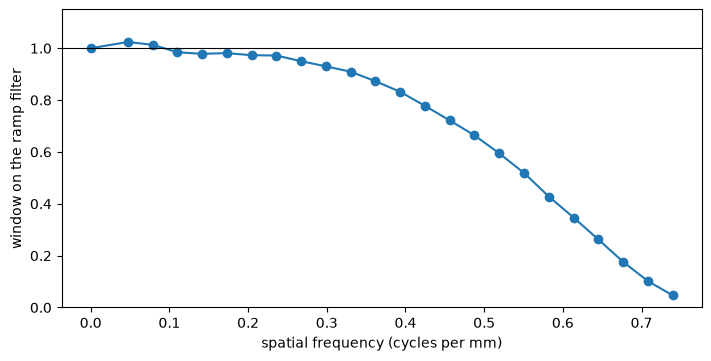

In [12]:
t0 = time.time()
window = preprocessing.fit_window(proj, proj_meta, system_matrix, io.CT.from_hu(scanner_hu, proj_meta), slice_thickness=1.25)
print(f"fitted in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(window.frequencies, window.values, 'o-')
ax.axhline(1, color='k', lw=0.8)
ax.set(xlabel='spatial frequency (cycles per mm)', ylabel='window on the ramp filter', ylim=(0, 1.15))
plt.show()

The fitted window stays close to 1 up to about 0.3 cycles per mm and falls to about 0.05 at 0.74 cycles per mm, the Nyquist frequency of the 0.662 mm pixels: it keeps more fine detail than the Hann window of the first part. Reconstructing with it:

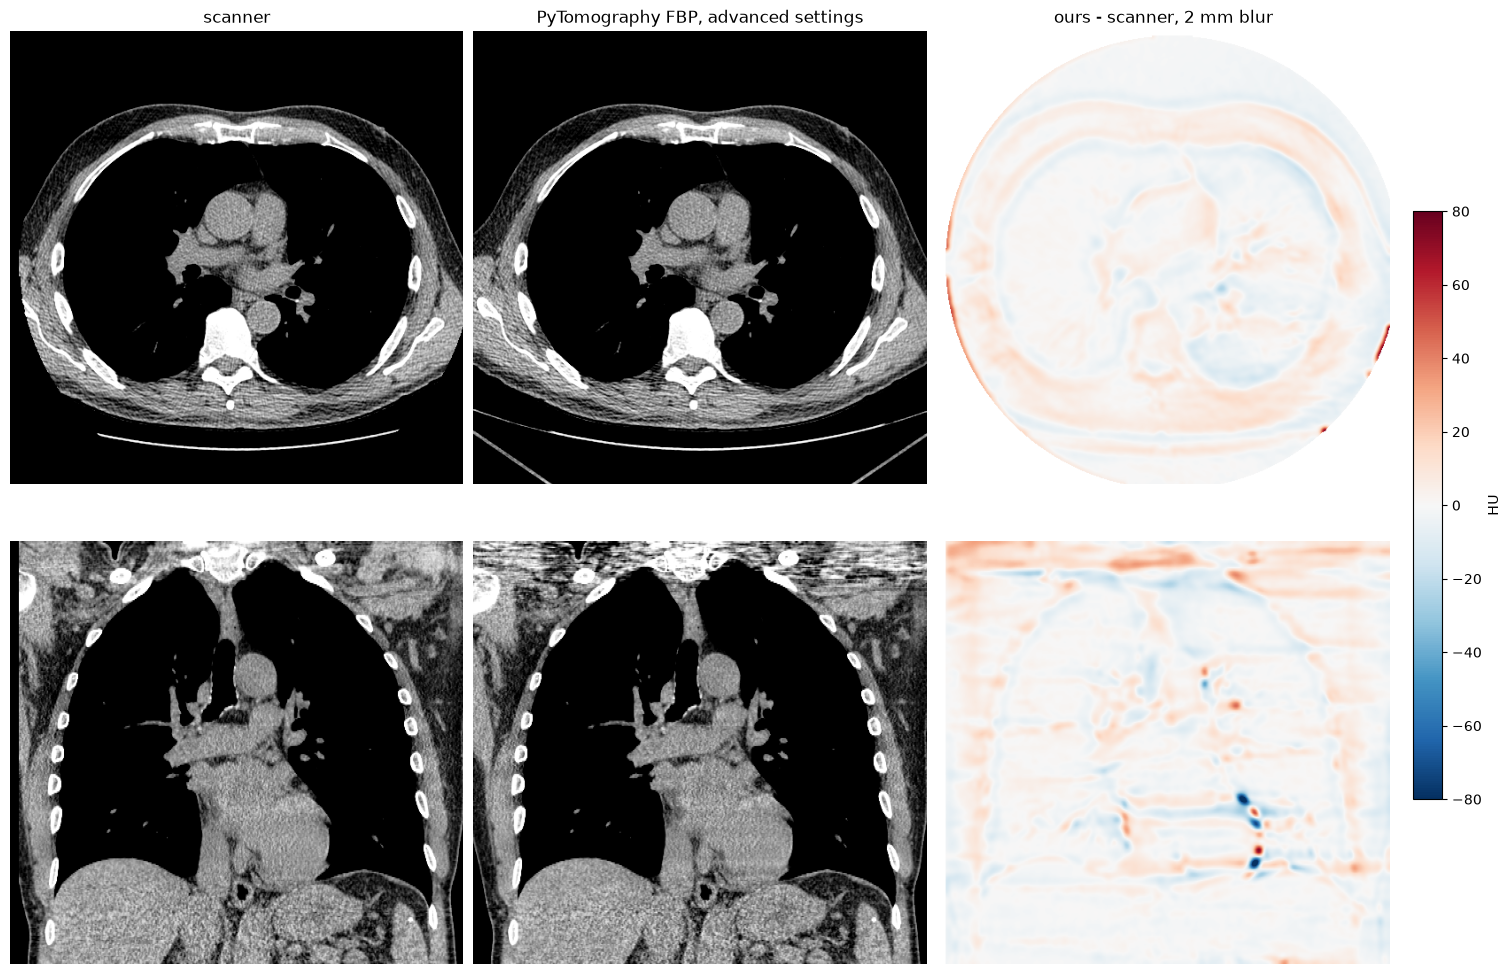

RMS difference over the body after a 2 mm blur: 9.6 HU


In [13]:
matched = FilteredBackProjection(proj, system_matrix, filter=window, slice_thickness=1.25)()
hu_matched = io.CT.to_hu(matched, proj_meta).cpu().numpy()
compare(hu_matched, 'PyTomography FBP, advanced settings')

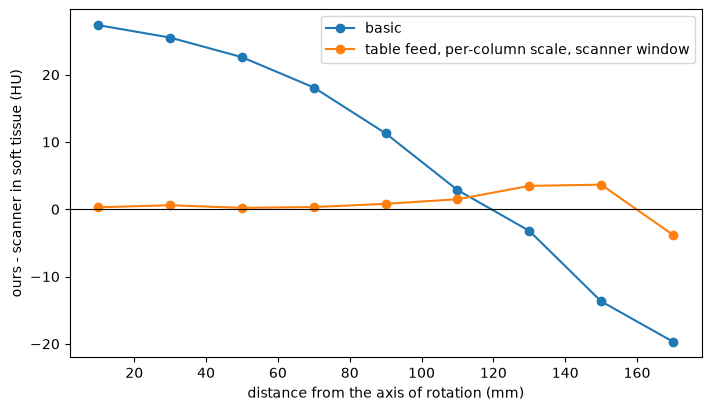

In [14]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(*trend_basic, 'o-', label='basic')
ax.plot(*radial_trend(hu_matched), 'o-', label='table feed, per-column scale, scanner window')
ax.axhline(0, color='k', lw=0.8)
ax.set(xlabel='distance from the axis of rotation (mm)', ylabel='ours - scanner in soft tissue (HU)')
ax.legend()
plt.show()

With the three settings, soft tissue agrees with the scanner within a few HU out to 15 cm from the axis, and the noise looks the same in both images: it is largely the same noise, since both come from the same projections. What still differs: streaks in our top slices, where the scan ends, and a spot by the heart, which moved between the views the two reconstructions combine.

## Save the images

`io.save_dicom` writes the image with the advanced settings as a DICOM CT series in HU, one file per slice, where `object_meta` places it in the patient. `slice_thickness=1.25` records the thickness each slice averages over (they are 1 mm apart). `reference=scanner_files[0]` gives it the patient, study and frame of reference of the scanner's images, so DICOM viewers show the two together.

In [15]:
saved = io.save_dicom(hu_matched, OUTPUT / 't_CT_GEN3' / 'fbp_matched', object_meta, units='HU', slice_thickness=1.25,
                      reference=scanner_files[0], series_description='FBP, advanced settings', overwrite=True)

## Next steps

- The same reader handles Siemens scanners with a flying focal spot: the collection's Siemens cases and ACR phantom reconstruct with the same code.

In [16]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 1.63, "peak_ram_gb": 14.5}
